=== 多核 BEM 求解有限域椭圆开孔受拉板问题 ===


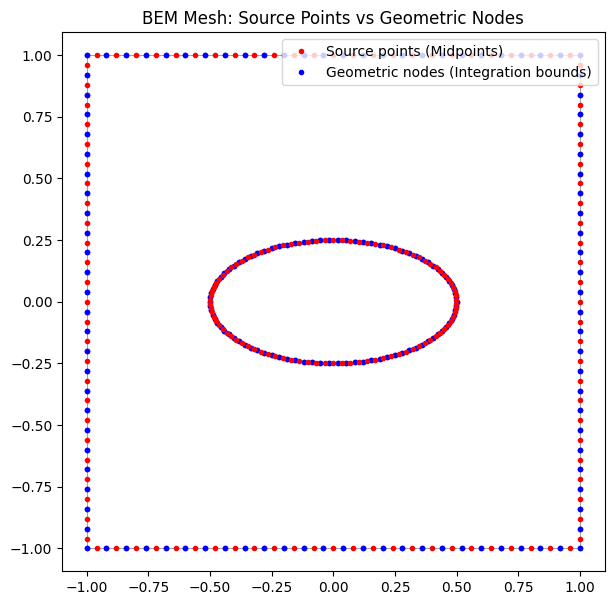

组装系统矩阵...
求解线性方程组...
提取近场物理场与有限差分应力...


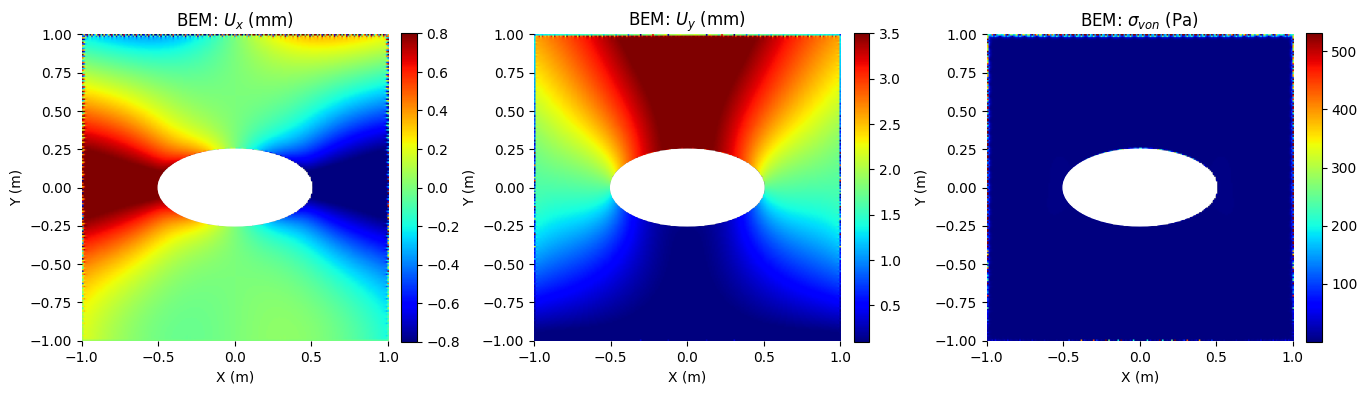

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数
# ==========================================
R_major = 0.5        
R_minor = 0.25       
L = 2.0              

tn = 1.0             
E = 1000.0           
nu = 0.3             

nu_eff = nu / (1.0 + nu)  
G_shear = E / (2.0 * (1.0 + nu))

print(f"=== 多核 BEM 求解有限域椭圆开孔受拉板问题 ===")

# ==========================================
# 2. 生成多连通域边界网格 (外方内椭圆)
# ==========================================
N_hole = 90          
N_side = 25          
N = N_side * 4 + N_hole

nodes = np.zeros((N, 2))       # 源点 (单元中点)
normals = np.zeros((N, 2))
lengths = np.zeros(N)
bnd_tag = np.zeros(N, dtype=int) 
endpoints = np.zeros((N, 4))   # 记录几何端点用于画图

idx = 0

def add_segment(x1, y1, x2, y2, tag):
    global idx
    nodes[idx] = [(x1 + x2) / 2, (y1 + y2) / 2] # 源点在中间
    endpoints[idx] = [x1, y1, x2, y2]           # 记录几何端点
    vx, vy = x2 - x1, y2 - y1
    L_j = np.hypot(vx, vy)
    lengths[idx] = L_j
    normals[idx] = [vy / L_j, -vx / L_j] 
    bnd_tag[idx] = tag
    idx += 1

# 外边界
coords_c = np.linspace(-L/2, L/2, N_side + 1)
for i in range(N_side): add_segment(coords_c[i], -L/2, coords_c[i+1], -L/2, 1)        
for i in range(N_side): add_segment(L/2, coords_c[i], L/2, coords_c[i+1], 2)          
for i in range(N_side): add_segment(coords_c[N_side-i], L/2, coords_c[N_side-i-1], L/2, 3) 
for i in range(N_side): add_segment(-L/2, coords_c[N_side-i], -L/2, coords_c[N_side-i-1], 4) 

# 内椭圆孔
theta = np.linspace(2 * np.pi, 0, N_hole + 1)
for i in range(N_hole):
    x1, y1 = R_major * np.cos(theta[i]), R_minor * np.sin(theta[i])
    x2, y2 = R_major * np.cos(theta[i+1]), R_minor * np.sin(theta[i+1])
    add_segment(x1, y1, x2, y2, 0)

# ==========================================
# 🌟 可视化：源点与几何端点的分布
# ==========================================
plt.figure(figsize=(7, 7))
# 画边界的蓝色几何端点 (Integration boundaries)
for i in range(N):
    x1, y1, x2, y2 = endpoints[i]
    plt.plot([x1, x2], [y1, y2], 'k-', lw=0.5, alpha=0.5)
    plt.plot(x1, y1, 'bo', markersize=3)
    plt.plot(x2, y2, 'bo', markersize=3)

# 画红色的源点 (Source points)
plt.plot(nodes[:, 0], nodes[:, 1], 'ro', markersize=3, label='Source points (Midpoints)')
plt.plot([], [], 'bo', markersize=3, label='Geometric nodes (Integration bounds)')

plt.legend(loc='upper right')
plt.title("BEM Mesh: Source Points vs Geometric Nodes")
plt.axis('equal')
plt.show()

# ==========================================
# 3. 组装与求解 (严格保持你原来的逻辑)
# ==========================================
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H, G = np.zeros((2*N, 2*N)), np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]
            tx, ty = -ny, nx
            r0, r1, c0, c1 = 2*i, 2*i+1, 2*j, 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                G[r0, c0] = tx*(g00*tx) + nx*(g11*nx); G[r0, c1] = tx*(g00*ty) + nx*(g11*ny)
                G[r1, c0] = ty*(g00*tx) + ny*(g11*nx); G[r1, c1] = ty*(g00*ty) + ny*(g11*ny)
            else:
                y_center = nodes[j]
                H00 = H01 = H10 = H11 = G00 = G01 = G10 = G11 = 0.0
                for g in range(n_gauss):
                    rx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx - x_source[0]
                    ry = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    rdx, rdy = rx/r, ry/r
                    dr_dn = rdx*nx + rdy*ny
                    log_1_r = np.log(1.0/r)
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01; H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01; G[r1, c0] = G10; G[r1, c1] = G11
    return H, G

t0 = time.time()
print("组装系统矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)

A, B = np.zeros((2*N, 2*N)), np.zeros(2*N)
u_known, u_val = np.zeros(2*N, dtype=bool), np.zeros(2*N)
t_known, t_val = np.zeros(2*N, dtype=bool), np.zeros(2*N)

for i in range(N):
    dof_x, dof_y = 2*i, 2*i+1
    tag = bnd_tag[i]
    if tag == 0:     
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = 0.0
    elif tag == 1:   
        u_known[dof_y] = True; u_val[dof_y] = 0.0  
        t_known[dof_x] = True; t_val[dof_x] = 0.0  
        if abs(nodes[i, 0]) < 1e-5:
            t_known[dof_x] = False
            u_known[dof_x] = True; u_val[dof_x] = 0.0
    elif tag == 2:   
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = 0.0
    elif tag == 3:   
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = tn
    elif tag == 4:   
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = 0.0

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]; B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]; B += G[:, k] * t_val[k]

print("求解线性方程组...")
X = np.linalg.solve(A, B)
u_bnd = np.where(u_known, u_val, X)
t_bnd = np.where(u_known, X, t_val)

# ==========================================
# 4. 提取观测区域内场数据 (严密对齐 CV-PINN)
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts, N = pts.shape[0], nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x, xi_y = pts[q, 0], pts[q, 1]
        u_x = u_y = 0.0
        for j in range(N):
            y_center = nodes[j]; L_j = lengths[j]
            nx, ny = normals[j, 0], normals[j, 1]; tx, ty = -ny, nx
            U00=U01=U10=U11=T00=T01=T10=T11=0.0
            
            for g in range(n_gauss):
                rx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx - xi_x
                ry = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx, rdy = rx/r, ry/r
                dr_dn = rdx*nx + rdy*ny; log_1_r = np.log(1.0/r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw; U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x, uj_y = u_bnd[2*j], u_bnd[2*j+1]
            tj_x, tj_y = t_bnd[2*j], t_bnd[2*j+1]
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0], u_out[q, 1] = u_x, u_y
    return u_out

print("提取近场物理场与有限差分应力...")
L_plot = L / 2.0
grid_size = 200 
eps = 1e-4

# 【修正回退】：完全恢复你最初的坐标系设定，没有任何 Margin
coords_1d = np.linspace(-L_plot, L_plot, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts_raw = np.c_[XX.ravel(), YY.ravel()]

# 【修正回退】：严格使用 1.02，保证布尔掩码与 CV-PINN 提取测试点完全等价
ellipse_val = (internal_pts_raw[:, 0] / R_major)**2 + (internal_pts_raw[:, 1] / R_minor)**2
valid_mask = (ellipse_val >= 1.02) 
internal_pts = internal_pts_raw[valid_mask]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

u_px = calc_internal_u_numba(internal_pts + np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps); du_dy = (u_py - u_my) / (2*eps)
eps_xx, eps_yy, eps_xy = du_dx[:, 0], du_dy[:, 1], 0.5 * (du_dx[:, 1] + du_dy[:, 0])

mu_lame = E / (2 * (1 + nu))
E_ps = E / (1.0 - nu**2)

sig_xx = E_ps * (eps_xx + nu * eps_yy)
sig_yy = E_ps * (eps_yy + nu * eps_xx)
sig_xy = 2 * mu_lame * eps_xy
sig_zz = 0.0 

von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + (sig_yy - sig_zz)**2 + (sig_zz - sig_xx)**2) + 3 * sig_xy**2)

U_X_map, U_Y_map, VM_map = [np.full(grid_size*grid_size, np.nan) for _ in range(3)]
U_X_map[valid_mask] = u_int[:, 0]
U_Y_map[valid_mask] = u_int[:, 1]
VM_map[valid_mask] = von_mises

# ==========================================
# 5. 绘图出图
# ==========================================
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 4.5))
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)
extent = [-L_plot, L_plot, -L_plot, L_plot]

ax0 = fig.add_subplot(gs[0, 0])
im0 = ax0.imshow(U_X_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet', vmin=-0.8, vmax=0.8)
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title('BEM: $U_x$ (mm)')
ax0.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))

ax1 = fig.add_subplot(gs[0, 1])
im1 = ax1.imshow(U_Y_map.reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent, cmap='jet', vmin=0.10, vmax=3.50)
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('BEM: $U_y$ (mm)')
ax1.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))

ax2 = fig.add_subplot(gs[0, 2])
# 因为贴近了边界，可能会有奇异高值，使用 vmax 截断显示效果更好
vmax_vm = np.nanpercentile(VM_map, 99.5)
im2 = ax2.imshow(VM_map.reshape(grid_size, grid_size), origin='lower', extent=extent, cmap='jet', vmin=0.3, vmax=vmax_vm)
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('BEM: $\sigma_{von}$ (Pa)')
ax2.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))

for ax in [ax0, ax1, ax2]:
    for spine in ax.spines.values(): spine.set_visible(False)

plt.show()

In [14]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os
from matplotlib.patches import Ellipse

os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

# ==========================================
# 0. 定义计算设备 (CUDA 支持)
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ==========================================
# 1. 物理参数与量纲配置 (严格对齐 BEM)
# ==========================================
R_major = 0.5        # 椭圆长轴 (m)
R_minor = 0.25       # 椭圆短轴 (m)
L = 2.0              # 方板边长 (2.0 m)

tn = 1.0             # 顶部拉向面力 (1.0 Pa)
E = 1000.0           # 杨氏模量 (1000 Pa)
nu = 0.3             # 泊松比

# 平面应力假设下的 Muskhelishvili 常数
kappa = (3.0 - nu) / (1.0 + nu)  
G = E / (2.0 * (1.0 + nu))

print(f"=== CV-PINN 求解有限域椭圆开孔受拉板 ===")
print(f"当前计算设备: {device}")
print(f"平面应力状态: kappa={kappa:.3f}, G={G:.3f}")

# ==========================================
# 2. 具备保角映射能力的网络架构
# ==========================================
class CVNN(nn.Module):
    def __init__(self, hidden=100):
        super().__init__()
        self.fc1 = nn.Linear(1, hidden, dtype=torch.cfloat)
        self.fc2 = nn.Linear(hidden, hidden, dtype=torch.cfloat)
        self.fc3 = nn.Linear(hidden, hidden, dtype=torch.cfloat)
        self.fc4 = nn.Linear(hidden, hidden, dtype=torch.cfloat) 
        self.out_phi = nn.Linear(hidden, 1, dtype=torch.cfloat)
        self.out_psi = nn.Linear(hidden, 1, dtype=torch.cfloat)
        
        # 使用 5 阶解析极点，大幅增强捕捉应力集中的能力
        self.poles = nn.Parameter(torch.zeros(10, 2)) 
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight.real)
                nn.init.xavier_uniform_(m.weight.imag)
                m.weight.data *= (1.0 / np.sqrt(2.0))
                if m.bias is not None:
                    nn.init.constant_(m.bias.real, 0.0)
                    nn.init.constant_(m.bias.imag, 0.0)

    def forward(self, z):
        x = torch.sin(self.fc1(z))
        x = torch.sin(self.fc2(x))
        x = torch.sin(self.fc3(x))
        x = torch.sin(self.fc4(x))
        
        phi_mlp = self.out_phi(x)
        psi_mlp = self.out_psi(x)
        
        # Joukowsky 共形映射
        c = np.sqrt(R_major**2 - R_minor**2)
        R_map = (R_major + R_minor) / 2.0
        
        root_term = torch.sqrt(z - c) * torch.sqrt(z + c)
        zeta = (z + root_term) / (2.0 * R_map)
        
        p_phi = torch.complex(self.poles[0:5, 0], self.poles[0:5, 1])
        p_psi = torch.complex(self.poles[5:10, 0], self.poles[5:10, 1])
        
        phi_poles = p_phi[0]/zeta + p_phi[1]/(zeta**2) + p_phi[2]/(zeta**3) + p_phi[3]/(zeta**4) + p_phi[4]/(zeta**5)
        psi_poles = p_psi[0]/zeta + p_psi[1]/(zeta**2) + p_psi[2]/(zeta**3) + p_psi[3]/(zeta**4) + p_psi[4]/(zeta**5)
        
        phi = phi_mlp + phi_poles
        psi = psi_mlp + psi_poles
        
        return phi, psi

# ==========================================
# 3. 物理场计算引擎 
# ==========================================
def get_phys_fields(model, x, y):
    z = torch.complex(x, y)
    phi, psi = model(z)

    phi_R, phi_I = phi.real, phi.imag
    psi_R, psi_I = psi.real, psi.imag

    dphi_dx_R = torch.autograd.grad(phi_R, x, grad_outputs=torch.ones_like(phi_R), create_graph=True, retain_graph=True)[0]
    dphi_dx_I = torch.autograd.grad(phi_I, x, grad_outputs=torch.ones_like(phi_I), create_graph=True, retain_graph=True)[0]
    dpsi_dx_R = torch.autograd.grad(psi_R, x, grad_outputs=torch.ones_like(psi_R), create_graph=True, retain_graph=True)[0]
    dpsi_dx_I = torch.autograd.grad(psi_I, x, grad_outputs=torch.ones_like(psi_I), create_graph=True, retain_graph=True)[0]
    
    dphi_dz = torch.complex(dphi_dx_R, dphi_dx_I)
    dpsi_dz = torch.complex(dpsi_dx_R, dpsi_dx_I)

    d2phi_dx2_R = torch.autograd.grad(dphi_dx_R, x, grad_outputs=torch.ones_like(dphi_dx_R), create_graph=True)[0]
    d2phi_dx2_I = torch.autograd.grad(dphi_dx_I, x, grad_outputs=torch.ones_like(dphi_dx_I), create_graph=True)[0]
    d2phi_dz2 = torch.complex(d2phi_dx2_R, d2phi_dx2_I)

    kappa_t = torch.tensor(float(kappa), device=x.device)
    G_t = torch.tensor(float(G), device=x.device)

    disp_complex = (kappa_t * phi - z * torch.conj(dphi_dz) - torch.conj(psi)) / (2.0 * G_t)
    u_x, u_y = disp_complex.real, disp_complex.imag

    sum_sig = 4.0 * dphi_dx_R
    diff_sig = 2.0 * (torch.conj(z) * d2phi_dz2 + dpsi_dz)
    
    sig_xx = (sum_sig - diff_sig.real) / 2.0
    sig_yy = (sum_sig + diff_sig.real) / 2.0
    sig_xy = diff_sig.imag / 2.0

    return u_x, u_y, sig_xx, sig_yy, sig_xy

# ==========================================
# 4. 边界条件 (添加了 device 传递)
# ==========================================
def get_bnd_loss():
    N_pts = 400 
    
    # ---- 1. 内部椭圆：自由边界 ----
    # 【修改】：张量直接在 device 上创建
    theta = torch.linspace(0, 2*np.pi, N_pts, device=device).view(-1, 1)
    x_hole = (R_major * torch.cos(theta)).requires_grad_(True)
    y_hole = (R_minor * torch.sin(theta)).requires_grad_(True)
    _, _, sig_xx, sig_yy, sig_xy = get_phys_fields(model, x_hole, y_hole)
    
    nx = R_minor * torch.cos(theta)
    ny = R_major * torch.sin(theta)
    norm = torch.sqrt(nx**2 + ny**2)
    nx, ny = nx/norm, ny/norm
    
    tx = sig_xx * nx + sig_xy * ny
    ty = sig_xy * nx + sig_yy * ny
    loss_hole = torch.mean(tx**2 + ty**2)

    # ---- 2. 外部矩形外框混合边界 ----
    # 【修改】：张量直接在 device 上创建
    coord_lin = torch.linspace(-L/2, L/2, N_pts, device=device).view(-1, 1).requires_grad_(True)
    
    y_top = torch.full_like(coord_lin, L/2).requires_grad_(True)
    _, _, _, sig_yy_top, sig_xy_top = get_phys_fields(model, coord_lin, y_top)
    loss_top = torch.mean((sig_yy_top - tn)**2 + (sig_xy_top - 0.0)**2)
    
    y_bot = torch.full_like(coord_lin, -L/2).requires_grad_(True)
    _, uy_bot, _, _, sig_xy_bot = get_phys_fields(model, coord_lin, y_bot)
    loss_bot = torch.mean((uy_bot * E)**2 + (sig_xy_bot - 0.0)**2)
    
    x_left = torch.full_like(coord_lin, -L/2).requires_grad_(True)
    x_right = torch.full_like(coord_lin, L/2).requires_grad_(True)
    _, _, sig_xx_l, _, sig_xy_l = get_phys_fields(model, x_left, coord_lin)
    _, _, sig_xx_r, _, sig_xy_r = get_phys_fields(model, x_right, coord_lin)
    loss_sides = torch.mean(sig_xx_l**2 + sig_xy_l**2 + sig_xx_r**2 + sig_xy_r**2)
    
    # ---- 3. 防止刚体平移的锚点 ----
    # 【修改】：张量直接在 device 上创建
    x_anc = torch.tensor([[0.0]], device=device, requires_grad=True)
    y_anc = torch.tensor([[-L/2]], device=device, requires_grad=True)
    ux_anc, _, _, _, _ = get_phys_fields(model, x_anc, y_anc)
    loss_anc = torch.mean((ux_anc * E)**2)

    return loss_hole + loss_top + loss_bot + loss_sides + loss_anc

# ==========================================
# 5. 训练主程序
# ==========================================
if __name__ == "__main__":
    # 【修改】：将模型发送至 GPU
    model = CVNN(hidden=100).to(device)
    
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    epochs_adam = 2500
    print(f"--- 阶段一：Adam 优化 ({epochs_adam} 次迭代) ---")
    
    t_start = time.time()
 
    for epoch in range(epochs_adam):
        optimizer.zero_grad()
        loss = get_bnd_loss()
        loss.backward()
        optimizer.step()
        if epoch % 500 == 0:
            print(f"Adam Epoch {epoch:4d} | Loss: {loss.item():.4e}")

    lbfgs_optimizer = torch.optim.LBFGS(
        model.parameters(), lr=1, max_iter=5000, max_eval=6000, 
        history_size=50, tolerance_grad=1e-7, tolerance_change=1e-9, 
        line_search_fn="strong_wolfe" 
    )

    print(f"\n--- 阶段二：L-BFGS 优化 (高精度收敛) ---")
    iter_count = [0] 

    def closure():
        lbfgs_optimizer.zero_grad()
        loss = get_bnd_loss()
        loss.backward()
        iter_count[0] += 1
        if iter_count[0] % 500 == 0:
            print(f"L-BFGS Iter {iter_count[0]:4d} | Loss: {loss.item():.4e}")
        return loss

    lbfgs_optimizer.step(closure)
    
    print(f"训练总耗时: {time.time() - t_start:.2f} 秒")
    
    # ==========================================
    # 6. 后处理对齐绘图
    # ==========================================
    L_plot = L / 2.0
    grid_size = 200
    coords_1d = np.linspace(-L_plot, L_plot, grid_size)
    XX, YY = np.meshgrid(coords_1d, coords_1d)

    # 精确屏蔽椭圆内部区域
    ellipse_val = (XX / R_major)**2 + (YY / R_minor)**2
    valid_mask = ellipse_val >= 1.02

    # 【修改】：确保测试点输入时在 GPU 上
    X_tensor = torch.tensor(XX[valid_mask].flatten(), dtype=torch.float32, device=device).view(-1, 1).requires_grad_(True)
    Y_tensor = torch.tensor(YY[valid_mask].flatten(), dtype=torch.float32, device=device).view(-1, 1).requires_grad_(True)

    model.eval()
    u_x_pred, u_y_pred, sig_xx_pred, sig_yy_pred, sig_xy_pred = get_phys_fields(model, X_tensor, Y_tensor)

    # 【修改】：提取数据时，先用 .cpu() 从显存转入内存，才能转换为 numpy 数组
    u_x_mm = u_x_pred.cpu().detach().numpy().flatten() * 1e3
    u_y_mm = u_y_pred.cpu().detach().numpy().flatten() * 1e3
    sig_xx_Pa = sig_xx_pred.cpu().detach().numpy().flatten()
    sig_yy_Pa = sig_yy_pred.cpu().detach().numpy().flatten()
    sig_xy_Pa = sig_xy_pred.cpu().detach().numpy().flatten()

    von_mises_Pa = np.sqrt(0.5 * ((sig_xx_Pa - sig_yy_Pa)**2 + (sig_yy_Pa)**2 + (-sig_xx_Pa)**2) + 3 * sig_xy_Pa**2)

    U_X_map, U_Y_map, VM_map = [np.full((grid_size, grid_size), np.nan) for _ in range(3)]
    U_X_map[valid_mask] = u_x_mm
    U_Y_map[valid_mask] = u_y_mm
    VM_map[valid_mask] = von_mises_Pa

    import matplotlib.gridspec as gridspec
    fig = plt.figure(figsize=(16, 4.5))
    gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)
    extent = [-L_plot, L_plot, -L_plot, L_plot]

    ax0 = fig.add_subplot(gs[0, 0])
    im0 = ax0.imshow(U_X_map, origin='lower', extent=extent, cmap='jet', vmin=-0.8, vmax=0.8)
    fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title('CV-PINN: $U_x$ (mm)')
    ax0.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))

    ax1 = fig.add_subplot(gs[0, 1])
    im1 = ax1.imshow(U_Y_map, origin='lower', extent=extent, cmap='jet', vmin=0.10, vmax=3.50)
    fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
    ax1.set_title('CV-PINN: $U_y$ (mm)')
    ax1.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))

    ax2 = fig.add_subplot(gs[0, 2])
    im2 = ax2.imshow(VM_map, origin='lower', extent=extent, cmap='jet', vmin=0.3, vmax=6.3)
    fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
    ax2.set_title('CV-PINN: $\sigma_{von}$ (Pa)')
    ax2.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))

    for ax in [ax0, ax1, ax2]:
        for spine in ax.spines.values(): spine.set_visible(False)

    plt.show()

=== CV-PINN 求解有限域椭圆开孔受拉板 ===
当前计算设备: cuda
平面应力状态: kappa=2.077, G=384.615
--- 阶段一：Adam 优化 (2500 次迭代) ---
Adam Epoch    0 | Loss: 1.5880e+00


KeyboardInterrupt: 

In [18]:
import torch
# ==========================================
# 7. CV-PINN 相对于 BEM 参考解的位移误差分析
# ==========================================
print("\n=== 开始计算 CV-PINN 与 BEM 之间的误差 ===")

# 【关键修改】：添加 device 参数，确保张量与 model 在同一设备
X_bem = torch.tensor(internal_pts[:, 0:1], dtype=torch.float32, device=device, requires_grad=True)
Y_bem = torch.tensor(internal_pts[:, 1:2], dtype=torch.float32, device=device, requires_grad=True)

# 2. CV-PINN 模型预测
model.eval() 
# 此时调用 get_phys_fields 将在 GPU 上顺利运行
u_pred_bem, v_pred_bem, _, _, _ = get_phys_fields(model, X_bem, Y_bem)

# 【关键修改】：.cpu() 必须放在 .detach() 之后，将 GPU 结果回传到 CPU 进行 NumPy 计算
u_pred_real = u_pred_bem.cpu().detach().numpy().flatten()
v_pred_real = v_pred_bem.cpu().detach().numpy().flatten()

# 提取 BEM 参考解 (单位: m)
u_bem_ref = u_int[:, 0]
v_bem_ref = u_int[:, 1]

# 3. 计算误差指标
norm_factor_ux = max(np.max(np.abs(u_bem_ref)), 1e-15)
norm_factor_uy = max(np.max(np.abs(v_bem_ref)), 1e-15)

err_ux_norm = np.abs(u_pred_real - u_bem_ref) / norm_factor_ux
err_uy_norm = np.abs(v_pred_real - v_bem_ref) / norm_factor_uy

L2_ux = np.linalg.norm(u_pred_real - u_bem_ref, 2) / max(np.linalg.norm(u_bem_ref, 2), 1e-15)
L2_uy = np.linalg.norm(v_pred_real - v_bem_ref, 2) / max(np.linalg.norm(v_bem_ref, 2), 1e-15)

print("-" * 50)
print(f"Relative L2 error Ux: {L2_ux:.3e}")
print(f"Relative L2 error Uy: {L2_uy:.3e}")
print(f"Max Normalized Error Ux: {err_ux_norm.max():.3e}")
print(f"Max Normalized Error Uy: {err_uy_norm.max():.3e}")
print("-" * 50)

print("-" * 50)
print(f"Relative L2 error Ux: {L2_ux:.3e}")
print(f"Relative L2 error Uy: {L2_uy:.3e}")
print(f"Max Normalized Error Ux: {err_ux_norm.max():.3e}")
print(f"Max Normalized Error Uy: {err_uy_norm.max():.3e}")
print("-" * 50)

# ==========================================
# 4. 映射回 2D 网格并绘图
# ==========================================
import matplotlib.gridspec as gridspec
from matplotlib.patches import Ellipse

# 确保 valid_mask 为 1D 数组 (BEM 代码中已经是 1D)
valid_mask_1d = valid_mask.flatten()

Err_X_map = np.full(grid_size * grid_size, np.nan)
Err_X_map[valid_mask_1d] = err_ux_norm

Err_Y_map = np.full(grid_size * grid_size, np.nan)
Err_Y_map[valid_mask_1d] = err_uy_norm

fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.25)
extent = [-L_plot, L_plot, -L_plot, L_plot]

# --- Ux 归一化误差图 ---
ax0 = fig.add_subplot(gs[0, 0])
im0 = ax0.imshow(Err_X_map.reshape(grid_size, grid_size), origin='lower', extent=extent, cmap='Reds', vmin=0)
ax0.set_xlabel('X (m)')
ax0.set_ylabel('Y (m)')
ax0.set_title('Normalized Absolute Error of $U_x$')
# 画出白色的中心椭圆遮盖，并添加一圈黑色边界线
ax0.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))
ax0.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='black', fill=False, linewidth=1.5, linestyle='-'))
fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)

# --- Uy 归一化误差图 ---
ax1 = fig.add_subplot(gs[0, 1])
im1 = ax1.imshow(Err_Y_map.reshape(grid_size, grid_size), origin='lower', extent=extent, cmap='Reds', vmin=0)
ax1.set_xlabel('X (m)')
ax1.set_ylabel('Y (m)')
ax1.set_title('Normalized Absolute Error of $U_y$')
# 画出白色的中心椭圆遮盖，并添加一圈黑色边界线
ax1.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='white', fill=True))
ax1.add_patch(Ellipse((0, 0), 2*R_major, 2*R_minor, color='black', fill=False, linewidth=1.5, linestyle='-'))
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

# 去除多余的边框，保持图片整洁
for ax in [ax0, ax1]:
    for spine in ax.spines.values(): spine.set_visible(False)

plt.show()


=== 开始计算 CV-PINN 与 BEM 之间的误差 ===


TypeError: only length-1 arrays can be converted to Python scalars